In [ ]:
import matplotlib.pyplot as plt
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from datetime import datetime
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.datasets import make_regression
from sklearn.metrics import mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
import seaborn as sns

## load dataset here

In [ ]:
# Set the path to the file you'd like to load
location=["Location1.csv", "Location2.csv", "Location3.csv", "Location4.csv"]
datasets=[]
for l in location:

  # Load the latest version
  df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "mubashirrahim/wind-power-generation-data-forecasting",
    l,
    # Provide any additional arguments like
    # sql_query or pandas_kwargs. See the
    # documenation for more information:
    # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
  )
  df["location"] = l.replace(".csv", "")
  datasets.append(df)
wind_data=pd.concat(datasets,ignore_index=True)
print("First 5 records:", wind_data.head())

/tmp/ipykernel_794/3029565163.py:7: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


100%|██████████| 853k/853k [00:00<00:00, 38.2MB/s]

Extracting zip of Location1.csv...



/tmp/ipykernel_794/3029565163.py:7: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'wind-power-generation-data-forecasting' dataset.


/tmp/ipykernel_794/3029565163.py:7: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'wind-power-generation-data-forecasting' dataset.


/tmp/ipykernel_794/3029565163.py:7: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'wind-power-generation-data-forecasting' dataset.
First 5 records:                   Time  temperature_2m  relativehumidity_2m  dewpoint_2m  \
0  2017-01-02 00:00:00            28.5                   85         24.5   
1  2017-01-02 01:00:00            28.4                   86         24.7   
2  2017-01-02 02:00:00            26.8                   91         24.5   
3  2017-01-02 03:00:00            27.4                   88         24.3   
4  2017-01-02 04:00:00            27.3                   88         24.1   

   windspeed_10m  windspeed_100m  winddirection_10m  winddirection_100m  \
0           1.44            1.26                146                 162   
1           2.06            3.99                151                 158   
2           1.30            2.78                148                 150   
3           1.30            2.69                 58                 105   
4           2.47            4.43                 58       

Previewing the dataset

In [ ]:
wind_data.head()

,Time,temperature_2m,relativehumidity_2m,dewpoint_2m,windspeed_10m,windspeed_100m,winddirection_10m,winddirection_100m,windgusts_10m,Power,location
0,2017-01-02 00:00:00,28.5,85,24.5,1.44,1.26,146,162,1.4,0.1635,Location1
1,2017-01-02 01:00:00,28.4,86,24.7,2.06,3.99,151,158,4.4,0.1424,Location1
2,2017-01-02 02:00:00,26.8,91,24.5,1.30,2.78,148,150,3.2,0.1214,Location1
3,2017-01-02 03:00:00,27.4,88,24.3,1.30,2.69,58,105,1.6,0.1003,Location1
4,2017-01-02 04:00:00,27.3,88,24.1,2.47,4.43,58,84,4.0,0.0793,Location1


In [ ]:
wind_data.temperature_2m.max()

101.7

Checking for null values

In [ ]:
wind_data.isnull().sum()

,0
Time,0
temperature_2m,0
relativehumidity_2m,0
dewpoint_2m,0
windspeed_10m,0
windspeed_100m,0
winddirection_10m,0
winddirection_100m,0
windgusts_10m,0
Power,0


## data preprocessing

In [ ]:

le_time = LabelEncoder()
le_time.fit(wind_data['Time'])
numerical_features_time = le_time.transform(wind_data['Time'])
wind_data["time_encoded"]=numerical_features_time
le_location = LabelEncoder()
le_location.fit(wind_data['location'])
numerical_features_location = le_location.transform(wind_data['location'])
wind_data["location_encoded"]=numerical_features_location
for num, wind_location in enumerate(le_location.classes_):
  print(num,wind_location)

  wind_data_preprocessed=wind_data.drop(columns=["location","Time"]).copy()

0 Location1
1 Location2
2 Location3
3 Location4


In [ ]:
len(wind_data.columns)

13

In [ ]:
wind_data.shape

(175200, 13)

In [ ]:
def get_categorical_temp():
  temp_categorical_features = []
  for i, row in wind_data.iterrows():
    temperature = row['temperature_2m']
   ### BEGIN YOUR CODE HERE ###
    if temperature >32:
       temp_category="nonfreezing"
    if temperature <=32:
      temp_category="freezing"
    temp_categorical_features.append(temp_category)
    ### END YOUR CODE HERE ###
  return temp_categorical_features

temp_categorical_features = get_categorical_temp()

In [ ]:
y=wind_data.Power

In [ ]:
wind_data.shape

(175200, 13)

In [ ]:
def get_categorical_date():
  date_categorical_features = []
  for i, row in wind_data.iterrows():
    dt=datetime.strptime(row['Time'],"%Y-%m-%d %H:%M:%S")
    temperature = row['Time']
    month=dt.month
   ### BEGIN YOUR CODE HERE ###

    if month >=3 and month <=5:
       date_category="spring"
    if month >=6 and month <=8:
      date_category="summer"
    if month >=9 and month <=11:
      date_category="autumn"
    if month ==12 or (month >=1 and month <=2):
      date_category="winter"
    date_categorical_features.append(date_category)
    ### END YOUR CODE HERE ###
  return date_categorical_features

date_categorical_features = get_categorical_date()
wind_data["season"]=date_categorical_features
print(wind_data["season"].value_counts())

season
spring    44160
summer    44160
autumn    43680
winter    43200
Name: count, dtype: int64


In [ ]:

X=wind_data_preprocessed.drop(columns=["Power"])
y=wind_data_preprocessed["Power"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=0)

In [ ]:
print(X_train.shape)
print(X_test.shape)


(131400, 10)
(43800, 10)


In [ ]:

pca=PCA(n_components=2)
principle_component=pca.fit_transform(X)
principle_component

array([[-21899.51113504,    -64.30545773],
       [-21898.51120057,    -63.63096786],
       [-21897.51259175,    -71.45632656],
       ...,
       [ 21897.4640461 ,   -277.84041616],
       [ 21898.46375992,   -280.64069524],
       [ 21899.46478202,   -271.43639796]])

## data visualization

Text(0.5, 1.0, 'Distrubution of Power')

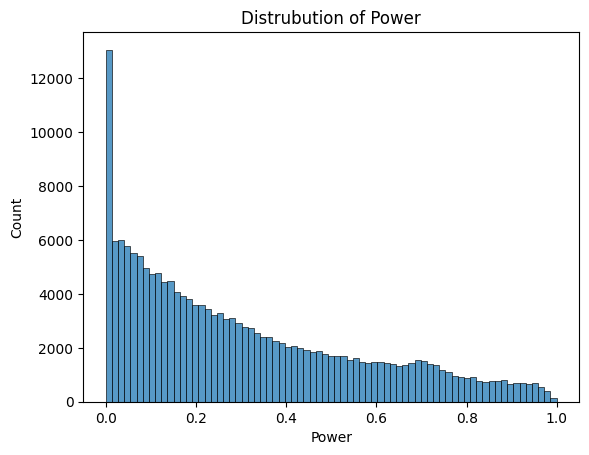

In [ ]:
wind_histogram=sns.histplot(data=wind_data_preprocessed,x="Power")
wind_histogram.set_title("Distrubution of Power")

Text(0.5, 1.0, 'Power Based on Location')

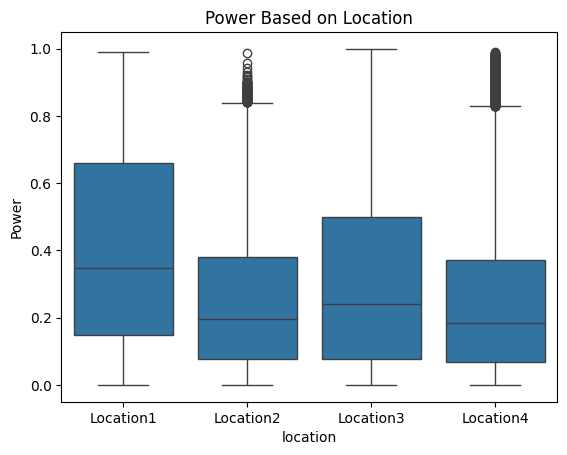

In [ ]:
wind_boxplot=sns.boxplot(data=wind_data,x="location", y="Power")
wind_boxplot.set_title("Power Based on Location")

Text(0.5, 1.0, 'Power Based on Season')

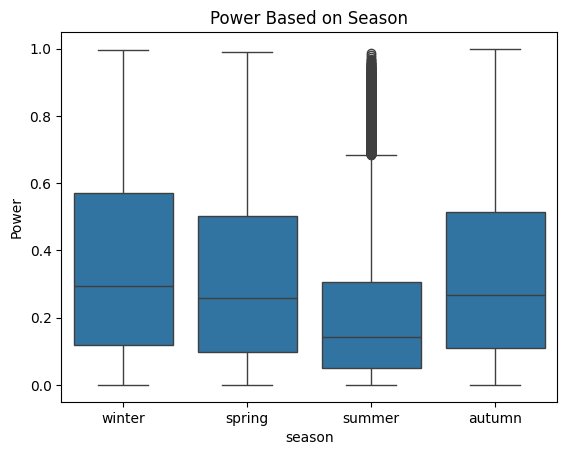

In [ ]:
wind_boxplot=sns.boxplot(data=wind_data,x="season", y="Power")
wind_boxplot.set_title("Power Based on Season")

## machine learning model testing

In [ ]:
reg = LinearRegression()
reg.fit(X_train, y_train)
print(reg.coef_)
print(reg.intercept_)
y_pred=reg.predict(X_test)
lg_mse=mean_squared_error(y_pred,y_test)
lg_mae=mean_absolute_error(y_pred,y_test)
lg_r2=r2_score(y_pred,y_test)
print(lg_mse)
print(lg_mae)
print(lg_r2)

[-9.46143979e-03 -3.42498072e-03  8.90984208e-03 -8.57596800e-02
  6.61137233e-02 -2.47616317e-05  7.79736084e-05  3.83989713e-02
 -1.84107716e-06 -3.30899241e-02]
0.3317067965575857
0.03492105921360747
0.14274161213394276
-0.12996987089371803


In [ ]:
rfr = RandomForestRegressor(random_state=0,max_depth=20)
rfr.fit(X_train, y_train)
y_pred_2=rfr.predict(X_test)
fr_mse=mean_squared_error(y_pred_2,y_test)
fr_mae=mean_absolute_error(y_pred_2,y_test)
fr_r2=r2_score(y_pred_2,y_test)
print(fr_mse)
print(fr_mae)
print(fr_r2)

0.01289728027450498
0.08123378098238329
0.7405098873478159


In [ ]:
dtr = DecisionTreeRegressor(random_state=0)
dtr.fit(X_train, y_train)
y_pred_3=dtr.predict(X_test)
dr_mse=mean_squared_error(y_pred_3,y_test)
dr_mae=mean_absolute_error(y_pred_3,y_test)
dr_r2=r2_score(y_pred_3,y_test)
print(dr_mse)
print(dr_mae)
print(dr_r2)

0.02451319157214612
0.10031993607305936
0.6299636848675736


In [ ]:
# STEP 1: Initialization
random_forest_model = RandomForestRegressor(min_samples_split=5,random_state=0)

# STEP 2: Training
random_forest_model.fit(X_train, y_train)

# STEP 3: Prediction
predictions = random_forest_model.predict(X_test)

# STEP 4: Evaluation
mean_absolute_error(y_test, predictions)

0.07937130679971213

Text(0, 0.5, 'Mean Absolute Error')

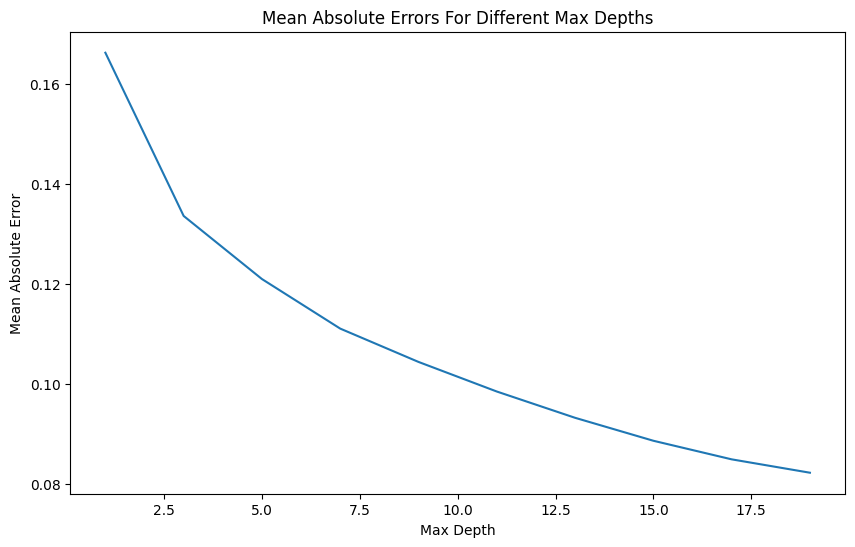

In [ ]:
mean_absolute_errors=[]
max_depths=range(1,21,2)
for i in max_depths:
  random_forest_model = RandomForestRegressor(max_depth=i, random_state=0)

# STEP 2: Training
  random_forest_model.fit(X_train, y_train)

# STEP 3: Prediction
  predictions = random_forest_model.predict(X_test)
  mean_absolute_errors.append(mean_absolute_error(y_test, predictions))
# STEP 4: Evaluation
plt.figure(figsize=(10,6))
plt.plot(max_depths,mean_absolute_errors)
plt.title('Mean Absolute Errors For Different Max Depths')
plt.xlabel("Max Depth")
plt.ylabel("Mean Absolute Error")